## 4.2 Importing Data

In [149]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [150]:
df = pd.read_csv("exoplanet_data.csv", comment = "#")

print(f"The shape of the dataset is {df.shape}, with 599 rows and 92 columns")
for columns in df.columns:
    print(columns)
print('The five columns that I have no idea what they mean are "defult_flag", "pl_controv_flag", "pl_bmassprov", "pl_bmassjerr1, "ttv_flag"')



The shape of the dataset is (599, 92), with 599 rows and 92 columns
pl_name
hostname
default_flag
sy_snum
sy_pnum
discoverymethod
disc_year
disc_facility
soltype
pl_controv_flag
pl_refname
pl_orbper
pl_orbpererr1
pl_orbpererr2
pl_orbperlim
pl_orbsmax
pl_orbsmaxerr1
pl_orbsmaxerr2
pl_orbsmaxlim
pl_rade
pl_radeerr1
pl_radeerr2
pl_radelim
pl_radj
pl_radjerr1
pl_radjerr2
pl_radjlim
pl_bmasse
pl_bmasseerr1
pl_bmasseerr2
pl_bmasselim
pl_bmassj
pl_bmassjerr1
pl_bmassjerr2
pl_bmassjlim
pl_bmassprov
pl_orbeccen
pl_orbeccenerr1
pl_orbeccenerr2
pl_orbeccenlim
pl_insol
pl_insolerr1
pl_insolerr2
pl_insollim
pl_eqt
pl_eqterr1
pl_eqterr2
pl_eqtlim
ttv_flag
st_refname
st_spectype
st_teff
st_tefferr1
st_tefferr2
st_tefflim
st_rad
st_raderr1
st_raderr2
st_radlim
st_mass
st_masserr1
st_masserr2
st_masslim
st_met
st_meterr1
st_meterr2
st_metlim
st_metratio
st_logg
st_loggerr1
st_loggerr2
st_logglim
sy_refname
rastr
ra
decstr
dec
sy_dist
sy_disterr1
sy_disterr2
sy_vmag
sy_vmagerr1
sy_vmagerr2
sy_kmag
sy_km

## 4.3 Reducing Data

In [151]:
# Planet Name: pl_name†, "Planet name most commonly used in the literature". The name that the planet is most refered to
# Host Name: hostname†, "Stellar name most commonly used in the literature". The most used name of the star that the planet orbits 
# Spectral Type: st_spectype, "Classification of the star based on their spectral characteristics following the Morgan-Keenan system". The spectral type (categorized by the surface temp) of the planets host star. 
# Equilibrium Tempuratire [K]: pl_eqt†, "The equilibrium temperature of the planet as modeled by a black body heated only by its host star, or for directly imaged planets, the effective temperature of the planet required to match the measured luminosity if the planet were a black body". The tempurature of the planet if it were a black body. 
# Planet Mass or Mass*sin(i)[Jupiter Mass]: pl_bmassj†, "Best planet mass estimate available, in order of preference: Mass, M*sin(i)/sin(i), or M*sin(i), depending on availability, and measured in Jupiter masses". The best estimate for the mass of the planet, measured in Jupiter masses. 

new_df = df.loc[:, ['pl_name', 'hostname', 'st_spectype', 'pl_eqt', 'pl_bmassj']].copy()

new_df.dropna(axis = 1)

print(f" The shape of the new dataset is {new_df.shape}, with 599 rows and 5 columns")

print(new_df.head())
print(new_df.tail())

 The shape of the new dataset is (599, 5), with 599 rows and 5 columns
    pl_name hostname st_spectype  pl_eqt  pl_bmassj
0   7 CMa c    7 CMa         NaN     NaN   0.912000
1   7 CMa c    7 CMa         NaN     NaN   0.870000
2  DMPP-1 b   DMPP-1         NaN     NaN   0.052859
3  DMPP-1 b   DMPP-1        F8 V   877.0   0.076362
4  DMPP-1 c   DMPP-1        F8 V  1239.0   0.030205
         pl_name   hostname st_spectype  pl_eqt  pl_bmassj
594    bet Pic c    bet Pic         NaN     NaN       9.00
595  eps Ind A b  eps Ind A        K2 V     NaN       3.25
596  eps Ind A b  eps Ind A        K5 V     NaN       6.50
597  eps Ind A b  eps Ind A        K5 V   275.0       6.31
598  eps Ind A b  eps Ind A         NaN     NaN       7.63


## 4.4 Analyze Data

In [152]:
print(df.value_counts("discoverymethod"))

print(f"The different methods are: {",".join(df["discoverymethod"].unique())}.")

print("Transit has 405, radial velocity has 121, microlensing has 61, imagine has 6,transit timing varitations has 3, ecplis timing variations has 2, and disk kinematics has 1. Transit has the most and disk kinematics has the least/")

print("Transit: When a planet passes a star, the light from the star dims a bit. If we observe a star and see the light dimming repeatedly, we can assume that a planet is oriting the star. ")

print("Radial Velocity: If there is a planet orbiting the star, its gravity will also made the star orbit a bit as well, around their center of mass. Measuring the radial velocity of the star can tell us characteristic about the planet like its mass and orbital period.")

print("Microlensing: Seeing how the gravity of the planet bends light. Using a background star, as a closer star passes it, it will csue the ligth to bend a bit. if that closer star has a planet orbiting it we would see another smaller bend of the light caused by the planet")

print("Transit Timing Variations: The same method as transit, but if these dimmings of light from the star don't happen at the expected time intervals, we can assume there is moe than one planet. Since the gravity of a second planet will pull ont he first planet, it would cuse the time inteverals of the dimming to change slightly.")

print("Eclipse Timing Variations: Similiar to the transit timing variations. If two stars eclipse, one starpasses over antoher one, we would expect this eclipse to happen at regular intervals. If there is a third object tho, liek a planet, it's gravity will pull on the stars motions causing the tming of the eclipse to change form out predicted timing. ")

print("Disk Kinematics: Young stars have a raotating disk of gas and dust arounf them. The motion of the dust and gas is predictabel, but if there is a planet inside the disk it changed the wya the dust and gas moves. Seeing an unpredicted motion in teh disk can signify a planet inside the disk.")



discoverymethod
Transit                      405
Radial Velocity              121
Microlensing                  61
Imaging                        6
Transit Timing Variations      3
Eclipse Timing Variations      2
Disk Kinematics                1
Name: count, dtype: int64
The different methods are: Radial Velocity,Transit,Disk Kinematics,Imaging,Microlensing,Transit Timing Variations,Eclipse Timing Variations.
Transit has 405, radial velocity has 121, microlensing has 61, imagine has 6,transit timing varitations has 3, ecplis timing variations has 2, and disk kinematics has 1. Transit has the most and disk kinematics has the least/
Transit: When a planet passes a star, the light from the star dims a bit. If we observe a star and see the light dimming repeatedly, we can assume that a planet is oriting the star. 
Radial Velocity: If there is a planet orbiting the star, its gravity will also made the star orbit a bit as well, around their center of mass. Measuring the radial velocity of t

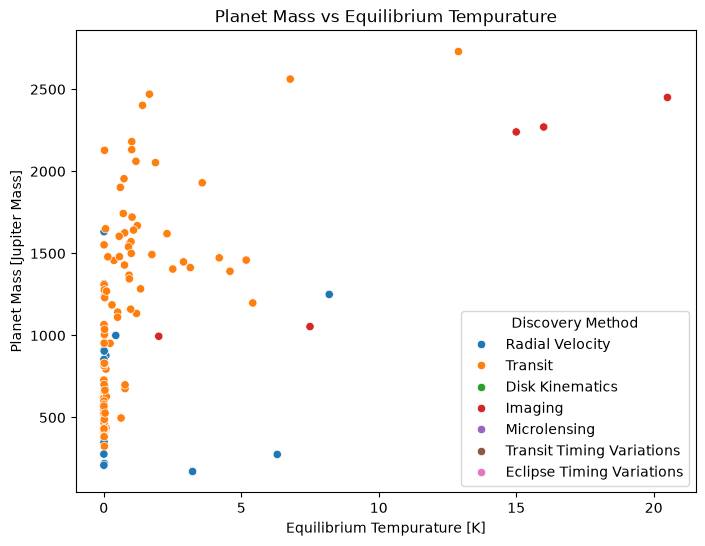

In [153]:
import seaborn as sns

plt.figure(figsize = (8,6))

sns.scatterplot(data = df, x = "pl_bmassj", y = "pl_eqt", hue = "discoverymethod")

plt.title("Planet Mass vs Equilibrium Tempurature")
plt.xlabel("Equilibrium Tempurature [K]")
plt.ylabel("Planet Mass [Jupiter Mass]")
plt.legend(title = "Discovery Method")
plt.show()

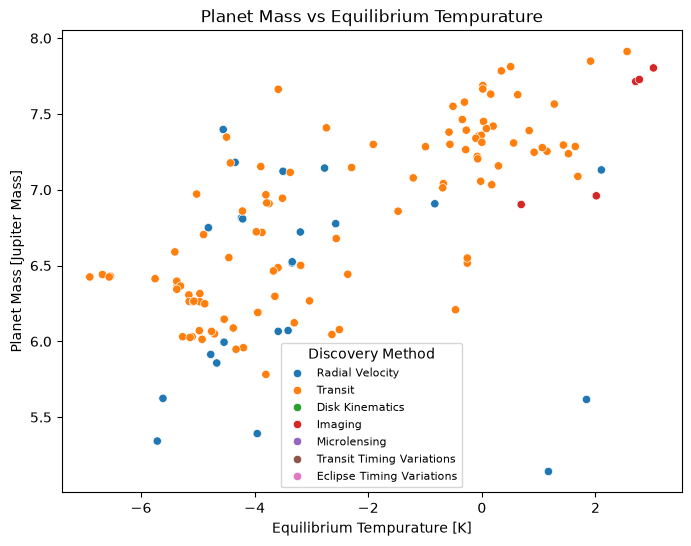

Based on the plot, planets found by the imaging methos are more likely to be massive.


In [154]:

x = np.log(df["pl_bmassj"])
df_clean = df[(df["pl_eqt"] > 0)] #had to add because the log wasnt working for the eqt values less than zero 
y = np.log(df_clean["pl_eqt"])


plt.figure(figsize = (8,6))

sns.scatterplot(data = df, x = x, y = y, hue = "discoverymethod")


plt.title("Planet Mass vs Equilibrium Tempurature")
plt.xlabel("Equilibrium Tempurature [K]")
plt.ylabel("Planet Mass [Jupiter Mass]")
plt.legend(title = "Discovery Method", fontsize = 8)
plt.show()

print("Based on the plot, planets found by the imaging methos are more likely to be massive.")

In [155]:
mass_df = df[df["pl_bmassj"] > 5]

coldest_index = mass_df["pl_eqt"].idxmin()

coldest_planet = mass_df.loc[coldest_index]

print(coldest_planet)

print(f"The planets name is {coldest_planet["pl_name"]}, in index {coldest_index}, with an equilibrium tempurature of {coldest_planet["pl_eqt"]} and a mass of {coldest_planet["pl_bmassj"]} Jupiter masses. It is orbiting a star of spectral class {coldest_planet["st_spectype"]}, which is a star cooler than the Sun.")



pl_name           eps Ind A b
hostname            eps Ind A
default_flag                0
sy_snum                     3
sy_pnum                     1
                     ...     
sy_gaiamagerr1       0.007374
sy_gaiamagerr2      -0.007374
rowupdate          2024-08-07
pl_pubdate            2024-09
releasedate        2024-08-07
Name: 597, Length: 92, dtype: object
The planets name is eps Ind A b, in index 597, with an equilibrium tempurature of 275.0 and a mass of 6.31 Jupiter masses. It is orbiting a star of spectral class K5 V, which is a star cooler than the Sun.


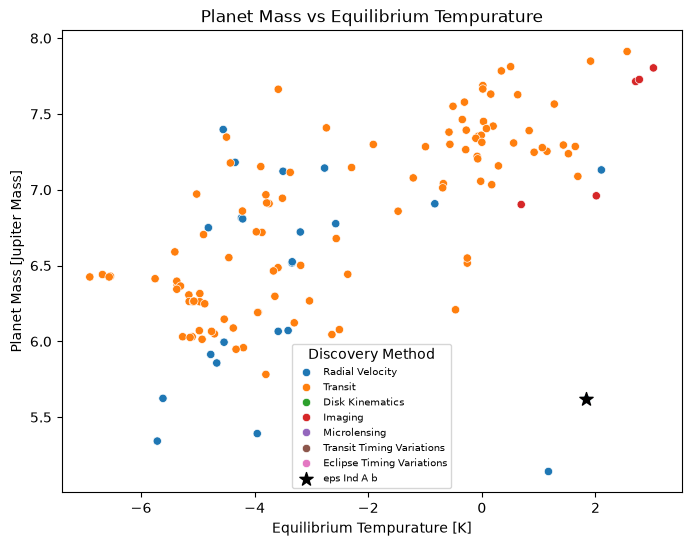

In [156]:
x = np.log(df["pl_bmassj"])
df_clean = df[(df["pl_eqt"] > 0)] #had to add because the log wasnt working for the eqt values less than zero 
y = np.log(df_clean["pl_eqt"])

x1 = np.log(coldest_planet["pl_bmassj"])
y1 = np.log(coldest_planet["pl_eqt"])

plt.figure(figsize = (8,6))

sns.scatterplot(data = df, x = x, y = y, hue = "discoverymethod")

plt.scatter(x1, y1, color = "Black", marker = "*", s = 100, label = coldest_planet["pl_name"])

plt.title("Planet Mass vs Equilibrium Tempurature")
plt.xlabel("Equilibrium Tempurature [K]")
plt.ylabel("Planet Mass [Jupiter Mass]")
plt.legend(title = "Discovery Method", fontsize = 7)
plt.show()

## 4.5 Check Your Answer 

In [157]:
print('The title of the paper is "A tempurature super-Jupiter imaged with JWST in the mid-infrared"')
print("The star Eps Ind A shows properties that would suggets a giant planet is orbiting it. JWST imaged a planet that matched hte measuremnt that led ot the suggestion of the planet, but it did not please the preivously claimed planet properies. The paper explains the data that JWST found")
print("Yes, the answer matched the exoplanet eps Ind A b")
print('Eps Ind A b is special because it "is the coldest exoplanet to have been directly imaged"')

print("Yes, the mass and equilibrium tempurature match the ones from the paper. We had exactly the same mass of 6.31 Jupiter masses, and roughly the same equilibruim tempurature with ours being 270K and theirs being 275K, so a 5K difference.")





The title of the paper is "A tempurature super-Jupiter imaged with JWST in the mid-infrared"
The star Eps Ind A shows properties that would suggets a giant planet is orbiting it. JWST imaged a planet that matched hte measuremnt that led ot the suggestion of the planet, but it did not please the preivously claimed planet properies. The paper explains the data that JWST found
Yes, the answer matched the exoplanet eps Ind A b
Eps Ind A b is special because it "is the coldest exoplanet to have been directly imaged"
Yes, the mass and equilibrium tempurature match the ones from the paper. We had exactly the same mass of 6.31 Jupiter masses, and roughly the same equilibruim tempurature with ours being 270K and theirs being 275K, so a 5K difference.
